## Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import utils
import seaborn as sns
import matplotlib.cm as cm

from pathlib import Path


path_figs = "./Figs/"
Path(path_figs).mkdir(parents=True, exist_ok=True)

fingers = ['1', '2', '3', '4', '5']
index_finger = utils.index_finger

iti = utils.iti
planTime = utils.planTime
feedbackTime = utils.feedbackTime

total_sub_num = utils.total_sub_num
conditions = utils.conditions

# Fill in after collection, or leave None to keep every subject in subjs.csv
sub_nums = None

utils.set_figure_style("1col")
sns.color_palette('colorblind')


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [3]:
# reload utils
import importlib
importlib.reload(utils)


<module 'utils' from '/Users/amin/projects/LearningDynamics/ChordAdaptationDynamics/SingleFingerGainGeneralization/utils.py'>

Load trial-level data written by `DatPreProcessing.ipynb` from `Single_Finger_Gain_Generalization_miscs/subjs.csv`.


In [4]:
subjs_path = utils.path_misc + 'subjs.csv'
if not Path(subjs_path).exists():
    raise FileNotFoundError(
        f"{subjs_path} not found. Run DatPreProcessing.ipynb after .dat files are copied in."
    )

subjs = pd.read_csv(subjs_path, sep='\t')

if sub_nums is not None:
    subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)

subjs


,subNum,BN,TN,TotalTrialNum,trial_num_within_condition,targetForce1,targetForce2,targetForce3,targetForce4,targetForce5,...,trialErrorType,num_targets,chord,condition,prev_condition,prev_perturbation,prev_trialCorr,transition,day,count
0,1,1,1,1,1,0.0,1.5,0.0,0.0,0.0,...,0,1,-^---,1.5,NaN,NaN,NaN,NaN,1,1
1,1,1,2,2,1,0.0,-3.0,0.0,0.0,0.0,...,0,1,-v---,-3.0,1.5,0.81,1.0,1.5->-3.0,1,1
2,1,1,3,3,2,0.0,-3.0,0.0,0.0,0.0,...,0,1,-v---,-3.0,-3.0,-0.31,1.0,-3.0->-3.0,1,1
3,1,1,4,4,1,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,-3.0,-0.26,1.0,-3.0->3.0,1,1
4,1,1,5,5,1,0.0,-1.5,0.0,0.0,0.0,...,0,1,-v---,-1.5,3.0,-0.54,1.0,3.0->-1.5,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3200,5,20,29,637,159,0.0,-1.5,0.0,0.0,0.0,...,0,1,-v---,-1.5,-3.0,-0.14,1.0,-3.0->-1.5,2,1
3201,5,20,30,638,160,0.0,-1.5,0.0,0.0,0.0,...,0,1,-v---,-1.5,-1.5,-0.49,1.0,-1.5->-1.5,2,1
3202,5,20,31,639,159,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,-1.5,0.27,1.0,-1.5->3.0,2,1
3203,5,20,32,640,160,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,3.0,0.29,1.0,3.0->3.0,2,1


In [4]:
subjs.T

,0,1,2,3,4,5,6,7,8,9,...,3195,3196,3197,3198,3199,3200,3201,3202,3203,3204
subNum,1,1,1,1,1,1,1,1,1,1,...,5,5,5,5,5,5,5,5,5,5
BN,1,1,1,1,1,1,1,1,1,1,...,20,20,20,20,20,20,20,20,20,20
TN,1,2,3,4,5,6,7,8,9,10,...,24,25,26,27,28,29,30,31,32,33
TotalTrialNum,1,2,3,4,5,6,7,8,9,10,...,632,633,634,635,636,637,638,639,640,641
trial_num_within_condition,1,1,2,1,1,2,3,4,3,4,...,157,160,158,159,160,159,160,159,160,161
targetForce1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce2,1.5,-3.0,-3.0,3.0,-1.5,-1.5,-3.0,-3.0,-1.5,-1.5,...,-3.0,1.5,-3.0,-3.0,-3.0,-1.5,-1.5,3.0,3.0,-1.5
targetForce3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
subjs_correct = utils.remove_error_trials(subjs).copy()

subjs_grouped = subjs_correct.groupby(['subNum', 'condition']).agg({
    'count': 'sum',
}).reset_index()

subjs_grouped


,subNum,condition,count
0,1,-3.0,157
1,1,-1.5,159
2,1,1.5,158
3,1,3.0,157
4,2,-3.0,150
5,2,-1.5,152
6,2,1.5,148
7,2,3.0,149
8,3,-3.0,160
9,3,-1.5,159


### Error rates


In [7]:
subjs_err = subjs.groupby(['subNum', 'trialCorr']).size().reset_index(name='num_trials')
subjs_err.sort_values(by=['subNum', 'trialCorr'])


,subNum,trialCorr,num_trials
0,1,0,10
1,1,1,631
2,2,0,42
3,2,1,599
4,3,0,9
5,3,1,632
6,4,0,56
7,4,1,585
8,5,0,17
9,5,1,624


### Produced force over trials (index finger), by target extent


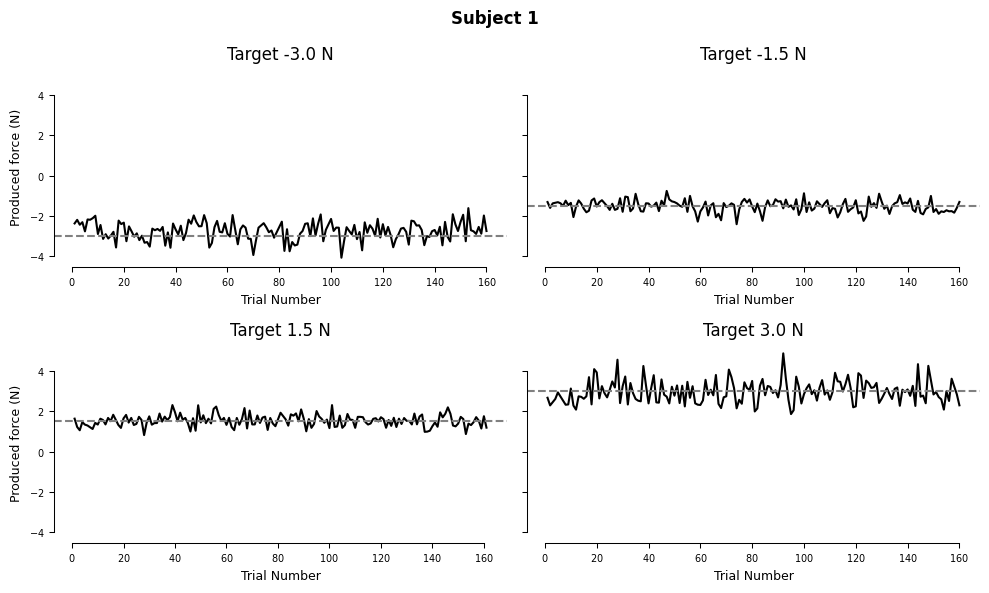

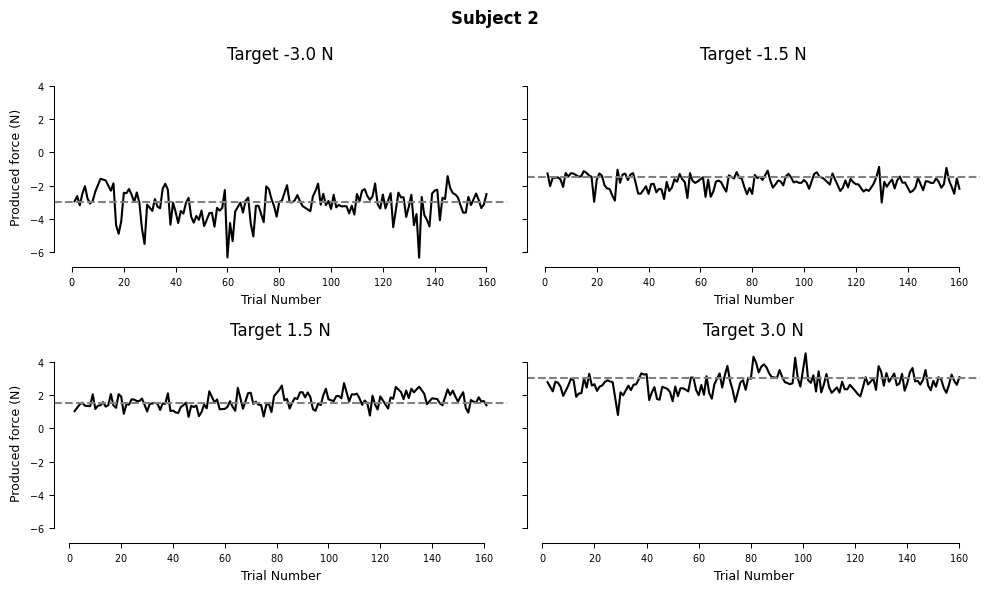

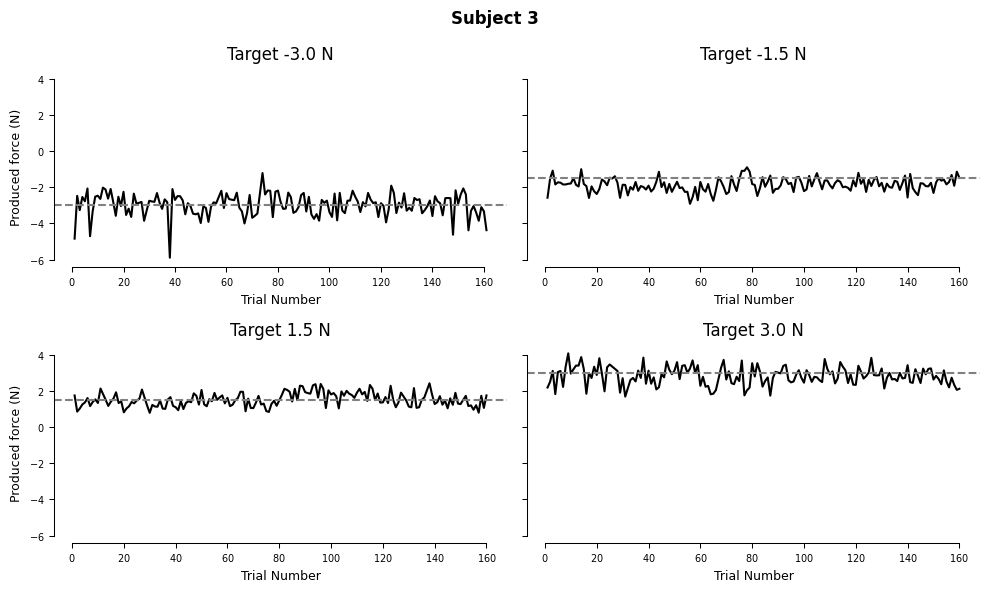

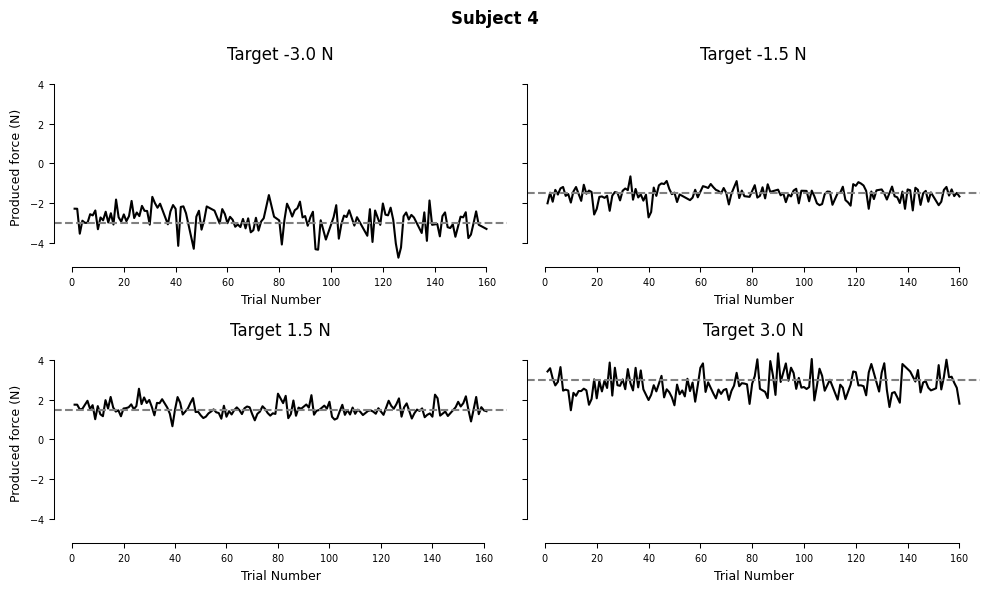

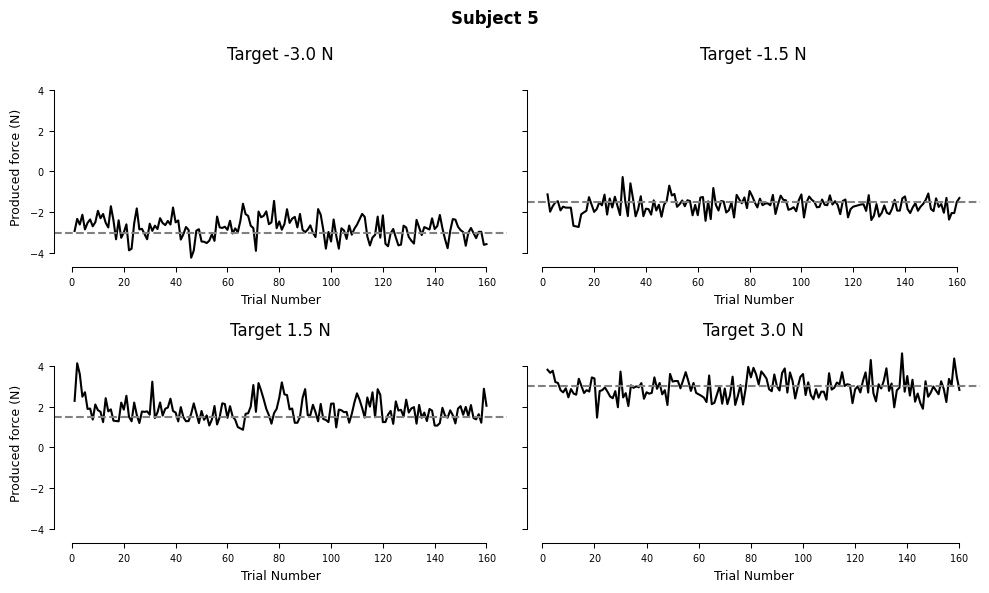

In [7]:
for subnum, subj_data in subjs_correct.groupby('subNum'):
    fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
    axs = axs.ravel()
    for ax, cond in zip(axs, conditions):
        cond_data = subj_data[subj_data['condition'] == cond]
        sns.lineplot(
            data=cond_data,
            x='trial_num_within_condition',
            y=f'endForce{index_finger}',
            ax=ax,
            color='black',
            errorbar=None,
        )
        ax.axhline(cond, color='gray', linestyle='--')
        ax.set_xlabel('Trial Number')
        ax.set_ylabel('Produced force (N)')
        ax.set_title(f'Target {cond} N')
    sns.despine(trim=True)
    fig.suptitle(f'Subject {subnum}')
    plt.tight_layout()
    plt.show()


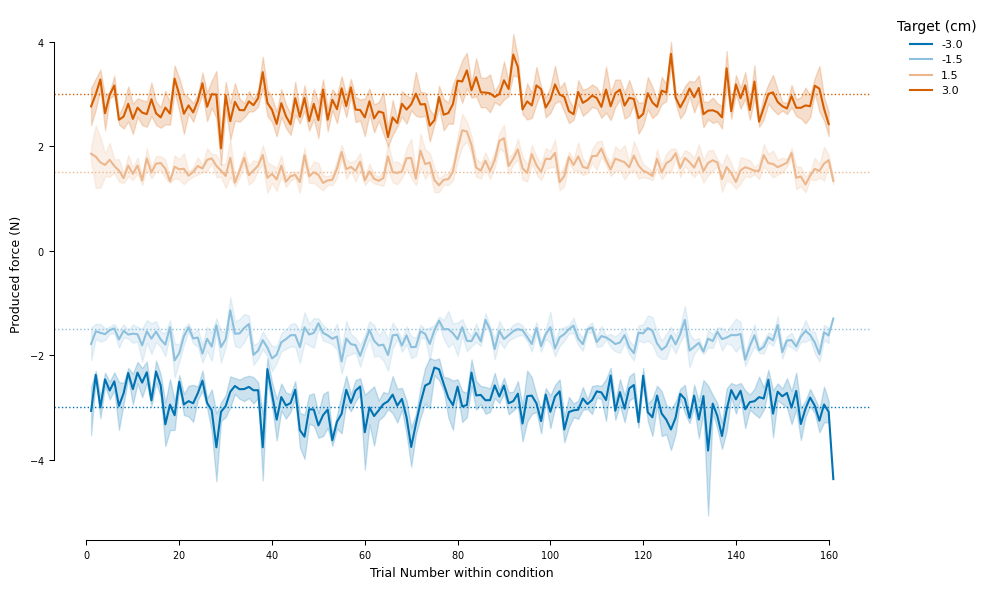

In [9]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]. Larger |target| → higher opacity.
palette = {
    -3.0: with_opacity(cb[0], 1.0),
    -1.5: with_opacity(cb[0], 0.45),
     1.5: with_opacity(cb[3], 0.45),
     3.0: with_opacity(cb[3], 1.0),
}

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=subjs_correct,
    x='trial_num_within_condition',
    y=f'endForce{index_finger}',
    hue='condition',
    hue_order=conditions,
    palette=palette,
    errorbar='se',
    ax=ax,
)
for cond in conditions:
    ax.axhline(cond, color=palette[cond], linestyle=':', linewidth=1.0, zorder=0)
ax.set_xlabel('Trial Number within condition')
ax.set_ylabel('Produced force (N)')
ax.legend(title='Target (cm)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'produced_force_by_trial.pdf', bbox_inches='tight')
plt.savefig(path_figs + 'produced_force_by_trial.png', dpi=300, bbox_inches='tight')
plt.show()
 

## Learning rates by transition

There are **16 transitions** (each of the 4 target extents to each of the 4). Method A is estimated **separately for each transition, within each participant**:

$$B = -\mathrm{cov}(X_{t+1},\, p_t)\,/\,\mathrm{var}(p_t)$$

`X` is the produced index force (`endForce`), not a target deviation. `p_t` is the perturbation on the previous trial.

An error trial is unusable for lag-1 learning: it has no sampled force, and its perturbation did not happen, so the **next** trial cannot use that `p_t` either. Pairs are kept only when **both** trial `t` and trial `t+1` are correct (`trials_for_learning_rate`).


# Method A — 16 transitions per participant


In [6]:
# X_{t+1} = produced force (endForce). Do not subtract the target:
# B = -cov(X_{t+1}, p_t) / var(p_t) is already mean-centered, and the
# design plot is the slope of regressing p_t onto produced X_{t+1}.

subjs_learn = utils.trials_for_learning_rate(subjs)
print(
    f"learning-rate trials: {len(subjs_learn)} / {len(subjs)} "
    f"(dropped errors + trials after an error + first trial of each subject)"
)

pairs = utils.learning_pairs(subjs)
B_by_trans = utils.learning_rates_by_transition(subjs)

print("pairs per transition (subject × from × to):")
print(
    pairs.groupby(['subNum', 'from', 'to']).size()
    .unstack('to')
    .reindex(index=pd.MultiIndex.from_product(
        [sorted(subjs['subNum'].unique()), conditions], names=['subNum', 'from']
    ), columns=conditions)
)
B_by_trans


learning-rate trials: 2946 / 3205 (dropped errors + trials after an error + first trial of each subject)
pairs per transition (subject × from × to):
to           -3.0  -1.5   1.5   3.0
subNum from                        
1      -3.0    37    40    37    40
       -1.5    40    39    39    39
        1.5    39    40    40    35
        3.0    38    40    38    39
2      -3.0    37    36    34    34
       -1.5    33    37    34    37
        1.5    35    32    36    35
        3.0    34    34    34    37
3      -3.0    40    39    40    37
       -1.5    40    40    38    39
        1.5    39    40    39    39
        3.0    39    39    38    37
4      -3.0    33    31    33    36
       -1.5    31    36    35    37
        1.5    33    35    35    32
        3.0    34    34    32    30
5      -3.0    38    39    39    37
       -1.5    38    39    39    38
        1.5    39    38    37    39
        3.0    36    35    38    38


,subNum,from,to,n_pairs,B
0,1,-3.0,-3.0,37,0.488971
1,1,-3.0,-1.5,40,0.233468
2,1,-3.0,1.5,37,-0.104355
3,1,-3.0,3.0,40,-0.433028
4,1,-1.5,-3.0,40,0.235699
...,...,...,...,...,...
75,5,1.5,3.0,39,0.193254
76,5,3.0,-3.0,36,-0.353028
77,5,3.0,-1.5,35,-0.011702
78,5,3.0,1.5,38,0.210535


### Transition learning rates vs next-trial extent

Same layout as the design-prediction figure: \(B\) against \(T_{t+1}\), one series per previous target \(T_t\). Gain adaptation predicts lines through the origin with slope \(\propto 1/T_t\); an additive offset predicts a flat line.


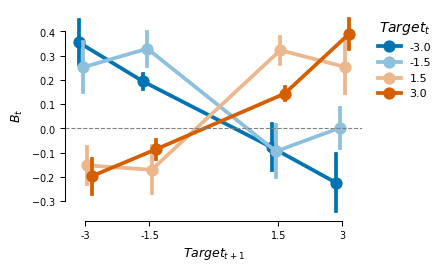

In [7]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]. Larger |target| → higher opacity.
palette = {
    -3.0: with_opacity(cb[0], 1.0),
    -1.5: with_opacity(cb[0], 0.45),
     1.5: with_opacity(cb[3], 0.45),
     3.0: with_opacity(cb[3], 1.0),
}

utils.set_figure_style('1.5col')
fig, ax = plt.subplots()
sns.pointplot(
    data=B_by_trans,
    x='to',
    y='B',
    hue='from',
    order=conditions,
    hue_order=conditions,
    palette=palette,
    errorbar='se',
    dodge=0.2,
    native_scale=True,
    ax=ax,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
# ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xticks(conditions)
ax.set_xticklabels([f'{c:g}' for c in conditions])
ax.set_xlabel(r'$Target_{t+1}$')
ax.set_ylabel(fr'$B_t$')
ax.legend(title=r'$Target_t$', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'transition_learning_rates.pdf', bbox_inches='tight')
plt.savefig(path_figs + 'transition_learning_rates.png', dpi=300, bbox_inches='tight')
plt.show()


## Summary results (Method A)

Here we summarize the **16 transition learning rates** \(B\) with the same two questions:

1. **Panel A (extent):** Within the same direction, does learning from a previous target of 1.5 N vs 3.0 N look gain-like at the next extent?
2. **Panel B (direction):** Is learning similar for **same-direction** vs **opposite-direction** transitions?

Pooling: within each participant, average the relevant transition \(B\)s first, then `sns.barplot` across subjects (± SEM).

Gain prediction for Method A: \(B \propto T_{t+1}/T_t\) (same-direction \(B\) positive; scales with next extent).

### Panel A — Same-direction extent transfer (1.5 ↔ 3)

Two plots by **previous** target extent (`|T_t|`). X-axis = next extent (`1.5 N`, `3.0 N`). Only **same-direction** transitions (`sign(T_t) == sign(T_{t+1})`); flexion and extension pooled by averaging \(B\) within participant.

**Gain prediction:** from 1.5 N → larger \(B\) at 3.0 N than at 1.5 N; from 3.0 N → smaller \(B\) at 1.5 N than at 3.0 N.  
**Extent-specific:** little transfer across extents within direction.

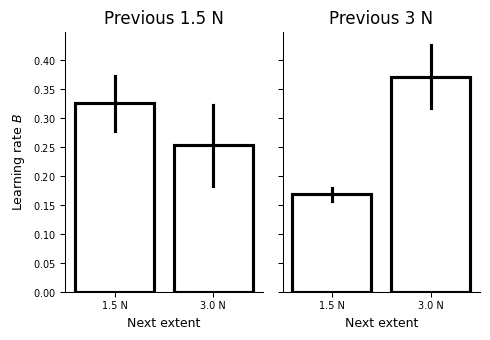

,subNum,from_extent,to_extent,B,to_label
0,1,1.5,1.5,0.333211,1.5 N
1,1,1.5,3.0,0.323311,3.0 N
2,1,3.0,1.5,0.200867,1.5 N
3,1,3.0,3.0,0.499311,3.0 N
4,2,1.5,1.5,0.145270,1.5 N


In [10]:
# --- Panel A: same-direction extent transfer (Method A B) ---
# Requires B_by_trans from the Method A cell above.

same_dir = np.sign(B_by_trans['from']) == np.sign(B_by_trans['to'])
ba = B_by_trans.loc[same_dir].copy()
ba['from_extent'] = ba['from'].abs()
ba['to_extent'] = ba['to'].abs()

# Within participant: mean B over ± at this from/to extent
panel_a = (
    ba.groupby(['subNum', 'from_extent', 'to_extent'], as_index=False)['B']
    .mean()
)
panel_a['to_label'] = panel_a['to_extent'].map({1.5: '1.5 N', 3.0: '3.0 N'})

to_order = ['1.5 N', '3.0 N']

fig, axs = plt.subplots(1, 2, figsize=(5, 3.5), sharey=True)

for ax, from_ext in zip(axs, [1.5, 3.0]):
    plot_data = panel_a[panel_a['from_extent'] == from_ext]

    sns.barplot(
        data=plot_data,
        x='to_label',
        y='B',
        order=to_order,
        errorbar='se',
        legend=False,
        ax=ax,
        fill=False,
        color='black',
    )
    # sns.stripplot(
    #     data=plot_data,
    #     x='to_label',
    #     y='B',
    #     order=to_order,
    #     ax=ax,
    #     color='black',
    #     alpha=0.5,
    # )

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Previous {from_ext:g} N')
    ax.set_xlabel('Next extent')
    ax.set_ylabel(r'Learning rate $B$' if ax is axs[0] else '')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_panel_A_extent_transfer.pdf', bbox_inches='tight')
plt.show()

panel_a.head()

### Panel B — Same direction vs opposite direction

One plot: mean Method A \(B\) for **same-direction** transitions vs **opposite-direction** transitions (all extents pooled within participant).

**Gain prediction:** same-direction \(B\) > 0; opposite-direction also structured by gain (not necessarily zero — depends on \(T_{t+1}/T_t\)), but the key contrast is whether learning is confined to one direction.  
**Direction-specific:** same-direction learning; opposite-direction near 0.

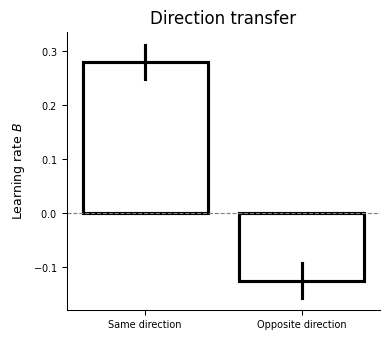

T-test same vs opposite direction: p-value: 0.002185837770263769, t-stat: 7.005370805621668, df: 4
T-test opposite direction vs 0: p-value: 0.016811904227421258, t-stat: -3.950432733957863, df: 4


In [9]:
# --- Panel B: same direction vs opposite direction (Method A B) ---
from scipy import stats

bb = B_by_trans.copy()
bb['direction_match'] = np.where(
    np.sign(bb['from']) == np.sign(bb['to']),
    'Same direction',
    'Opposite direction',
)

# Within participant: mean B over all transitions in each pool
panel_b = (
    bb.groupby(['subNum', 'direction_match'], as_index=False)['B']
    .mean()
)

match_order = ['Same direction', 'Opposite direction']

fig, ax = plt.subplots(figsize=(4, 3.5))

sns.barplot(
    data=panel_b,
    x='direction_match',
    y='B',
    order=match_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Direction transfer')
ax.set_xlabel('')
ax.set_ylabel(r'Learning rate $B$')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_panel_B_direction_transfer.pdf', bbox_inches='tight')
plt.show()

panel_b.head(10)

# statistical tests
result = stats.ttest_rel(
    panel_b.loc[panel_b['direction_match'] == 'Same direction', 'B'],
    panel_b.loc[panel_b['direction_match'] == 'Opposite direction', 'B'],
)
print(
    f"T-test same vs opposite direction: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

result = stats.ttest_1samp(
    panel_b.loc[panel_b['direction_match'] == 'Opposite direction', 'B'],
    0,
)
print(
    f"T-test opposite direction vs 0: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)